**Задача:** Классификация МРТ-снимков поясничного отдела позвоночника на 3 класса патологий: Herniated Disc (Грыжа диска), No Stenosis (Норма) и Thecal Sac (Сужение канала/Стеноз).

**Данные:** Набор данных Lumbar Spinal MRI Dataset.

**Цель:** Разработать и обучить две модели — собственную сверточную нейронную сеть (CNN) с нуля и модель с предобученными весами (ResNet18), а затем провести их сравнительный анализ.

*Я решала задачу медицинской классификации изображений. Для этого я провела разведочный анализ данных (EDA), в ходе которого обнаружила сильный дисбаланс классов, особенно в тестовой выборке. **Для решения задачи я реализовала две архитектуры: собственную CNN (4 блока свертки) и предобученную на ImageNet сеть ResNet18 с заменой последнего слоя.** В ходе эксперимента я выяснила, что обучение с нуля на малом наборе данных приводит к застреванию модели в локальном минимуме, тогда как использование предобученных признаков (Transfer Learning) позволяет модели успешно распознавать сложные патологии, несмотря на дефекты тестовой выборки*

**1. Установка библиотек и импорты**


В этом блоке я подключаю все необходимые библиотеки для работы с изображениями, обучения нейросетей и визуализации. Я фиксирую сиды (SEED = 42), чтобы результаты обучения были воспроизводимы при повторных запусках. Также я проверяю, доступен ли GPU (cuda), так как обучение сверточных сетей на процессоре занимает слишком много времени.

In [1]:
%pip install kagglehub --quiet

import os, time, copy, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision.transforms as T
import torchvision.models as models
from torchvision.datasets import ImageFolder

from sklearn.metrics import (
    classification_report, confusion_matrix
)

# Сиды
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| Torch:", torch.__version__)

Device: cuda | Torch: 2.11.0+cu130


**2. Загрузка датасета и пути**


Здесь я скачиваю датасет с Kaggle и прописываю пути к папкам. При анализе структуры архива я обнаружила, что автор датасета сделал двойную вложенность папок (LumbarSpinalStenosis/LumbarSpinalStenosis/train), поэтому пути сформированы именно таким образом, чтобы избежать ошибки FileNotFoundError. Я также проверяю список классов, который автоматически считывается из названий папок.

In [2]:
import os
import kagglehub

ROOT = kagglehub.dataset_download("abdullahkhan70/lumbar-spinal-mri-dataset")

TRAIN_DIR = os.path.join(ROOT, "LumbarSpinalStenosis", "LumbarSpinalStenosis", "train")
TEST_DIR  = os.path.join(ROOT, "LumbarSpinalStenosis", "LumbarSpinalStenosis", "test")

classes = sorted(os.listdir(TRAIN_DIR))
print("Классы:", classes)

100%|██████████| 340M/340M [00:21<00:00, 16.3MB/s]

Extracting files...


Классы: ['Herniated Disc', 'No Stenosis', 'Thecal Sac']


**3. EDA (Визуализация и баланс классов)**


В этом блоке я провожу разведочный анализ данных (EDA). Сначала я вывожу по одному примеру изображения для каждого класса, чтобы оценить морфологию снимков. Затем я строю гистограммы распределения классов и обнаруживаю, что в тестовой выборке класса Thecal Sac оказалось всего 13 изображений на фоне 1200–1500 картинок других классов, что сильно исказит итоговую метрику Accuracy.

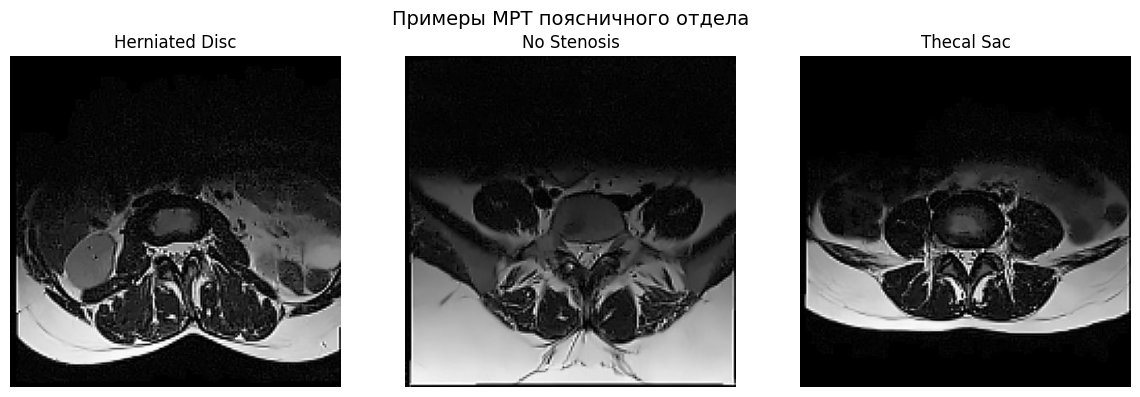

In [3]:
fig, axes = plt.subplots(1, len(classes), figsize=(4 * len(classes), 4))
for ax, cls in zip(axes, classes):
    cls_path = os.path.join(TRAIN_DIR, cls)
    img_name = os.listdir(cls_path)[0]
    img = Image.open(os.path.join(cls_path, img_name)).convert("L")
    ax.imshow(img, cmap="gray")
    ax.set_title(cls)
    ax.axis("off")
plt.suptitle("Примеры МРТ поясничного отдела", fontsize=14)
plt.tight_layout(); plt.show()

Train: {'Herniated Disc': 3063, 'No Stenosis': 3152, 'Thecal Sac': 4733}
Test:  {'Herniated Disc': 1218, 'No Stenosis': 1507, 'Thecal Sac': 13}


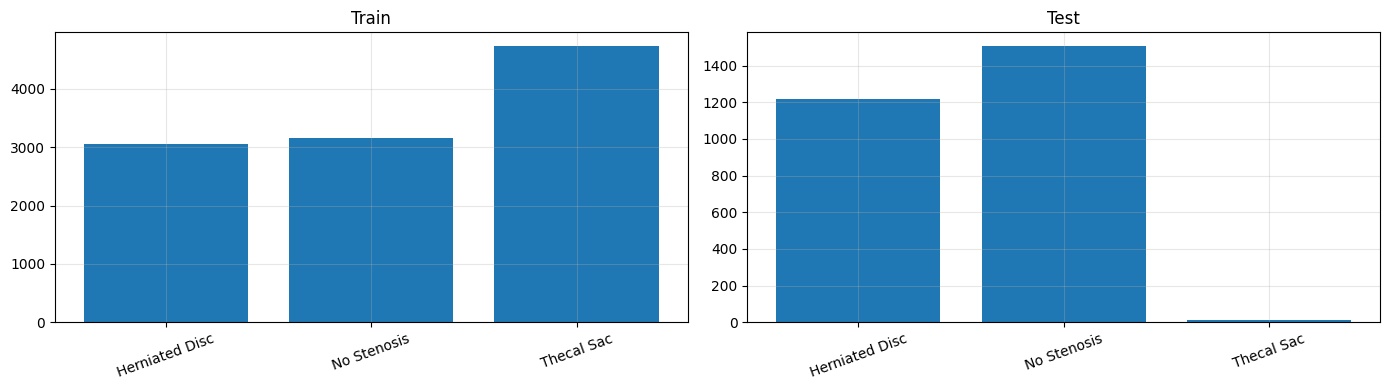

In [4]:
counts_train = {cls: len(os.listdir(os.path.join(TRAIN_DIR, cls))) for cls in classes}
counts_test  = {cls: len(os.listdir(os.path.join(TEST_DIR,  cls))) for cls in classes}

print("Train:", counts_train)
print("Test: ", counts_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, counts, ttl in zip(axes, [counts_train, counts_test], ["Train", "Test"]):
    ax.bar(list(counts.keys()), list(counts.values()))
    ax.set_title(ttl)
    ax.tick_params(axis='x', rotation=20)
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**4. Предобработка и DataLoader**


Здесь я настраиваю предобработку данных, конвертируя черно-белые МРТ в три канала (RGB) для совместимости с предобученной ResNet18. Для тренировочной выборки я добавляю аугментации (повороты и отражения), чтобы бороться с переобучением. Далее я стратифицированно разделяю данные на train и val (80/20) и оборачиваю их в DataLoader для подачи батчами.

In [5]:
IMG_SIZE   = 224   #ResNet18 ожидает 224x224
BATCH_SIZE = 32

#МРТ один канал, но я конвертирую в 3 канала, чтобы использовать предобученный ResNet
train_tfms = T.Compose([
    T.Grayscale(num_output_channels=3),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std =[0.229, 0.224, 0.225]),
])

eval_tfms = T.Compose([
    T.Grayscale(num_output_channels=3),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std =[0.229, 0.224, 0.225]),
])

# ImageFolder автоматически определит классы по подпапкам
full_train = ImageFolder(TRAIN_DIR, transform=train_tfms)
full_test  = ImageFolder(TEST_DIR,  transform=eval_tfms)

# Проверим порядок классов, чтобы корректно подписывать матрицу ошибок
print("Классы ImageFolder:", full_train.classes, full_train.class_to_idx)

# Разделяем train на train/val (80/20) стратифицированно по индексам
from collections import defaultdict
from sklearn.model_selection import train_test_split

targets = np.array(full_train.targets)
idx_train, idx_val = train_test_split(
    np.arange(len(targets)),
    test_size=0.2,
    random_state=SEED,
    stratify=targets,
)

train_subset = torch.utils.data.Subset(full_train, idx_train)
val_subset   = torch.utils.data.Subset(full_train, idx_val)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_subset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(full_test,    batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train: {len(train_subset)}, Val: {len(val_subset)}, Test: {len(full_test)}")

Классы ImageFolder: ['Herniated Disc', 'No Stenosis', 'Thecal Sac'] {'Herniated Disc': 0, 'No Stenosis': 1, 'Thecal Sac': 2}
Train: 8758, Val: 2190, Test: 2738


**5. Архитектура 1 (Собственная CNN)**


В этом блоке я описываю архитектуру собственной сверточной нейросети, состоящую из четырех блоков свертки с пакетной нормализацией и пулингом. После сверточных слоев я добавляю полносвязные слои с Dropout для регуляризации. В конце я проверяю выходной размер сети, чтобы убедиться, что она выдает 3 значения (по количеству классов).

In [6]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm2d(128)

        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)

        # 224 -> 112 -> 56 -> 28 -> 14 после 4 пулингов
        self.fc1 = nn.Linear(128 * 14 * 14, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)

# Проверка
_m = SimpleCNN(num_classes=3).to(device)
with torch.no_grad():
    print(_m(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)).shape)

torch.Size([2, 3])


**6. Вспомогательные функции обучения**


Здесь я реализую функции для обучения и оценки модели, добавив в тренировочный цикл вывод прогресса каждые 50 батчей для контроля времени. Функция evaluate работает без вычисления градиентов, что экономит память и ускоряет валидацию. Цикл fit объединяет это в полный процесс обучения с оптимизатором Adam и механизмом ранней остановки (Early Stopping).

In [7]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    t0 = time.time()

    for i, (xb, yb) in enumerate(loader):
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)

        # Выводим прогресс каждые 50 батчей, чтобы видеть, что идет работа
        if (i + 1) % 50 == 0:
            print(f"  [batch {i+1}/{len(loader)}] loss: {loss.item():.4f}, time: {time.time()-t0:.1f}s")

    return running_loss / total, correct / total

In [9]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = criterion(out, yb)
        running_loss += loss.item() * xb.size(0)
        pred = out.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)
        y_true.extend(yb.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())
    return (running_loss / total, correct / total,
            np.array(y_true), np.array(y_pred))

def fit(model, train_loader, val_loader, epochs=5, lr=1e-3,
        weight_decay=0.0, patience=2, title="Model"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )
    history = {"train_loss": [], "val_loss": [],
               "train_acc": [],  "val_acc": [], "time": []}
    best_val_loss, best_state, no_improve = float("inf"), None, 0

    for epoch in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step(va_loss)
        dt = time.time() - t0

        for k, v in zip(["train_loss","val_loss","train_acc","val_acc","time"],
                        [tr_loss, va_loss, tr_acc, va_acc, dt]):
            history[k].append(v)

        print(f"[{title}] Ep {epoch+1:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
              f"lr {optimizer.param_groups[0]['lr']:.2e} | {dt:.1f}s")

        if va_loss < best_val_loss - 1e-4:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping on epoch {epoch+1}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history

**7. Обучение собственной CNN**


Я запускаю обучение SimpleCNN на 5 эпох. Как видно из логов ниже, модель застревает на точности около 43% и не учится дальше. Скорее всего, из-за сложности медицинских снимков сеть выучила простое правило — предсказывать один и тот же класс, и перестала извлекать новые признаки.

In [10]:
import time

cnn_model = SimpleCNN(num_classes=3).to(device)

#запускаем обучение:
#epochs=5 (вместо 10, чтобы не ждать долго на CPU)
#patience=2 (если 2 эпохи подряд нет улучшений — стоп)
#добавлен print каждые 50 батчей внутри train_one_epoch
hist_cnn = fit(
    cnn_model,
    train_loader,
    val_loader,
    epochs=5,
    lr=1e-3,
    weight_decay=1e-5,
    patience=2,
    title="SimpleCNN"
)

  [batch 50/274] loss: 1.0594, time: 10.5s
  [batch 100/274] loss: 1.0652, time: 18.0s
  [batch 150/274] loss: 1.0960, time: 25.6s
  [batch 200/274] loss: 1.0554, time: 33.0s
  [batch 250/274] loss: 1.0933, time: 40.5s
[SimpleCNN] Ep 01/5 | train loss 1.3594 acc 0.4221 | val loss 1.0786 acc 0.4324 | lr 1.00e-03 | 54.1s
  [batch 50/274] loss: 1.0350, time: 8.3s
  [batch 100/274] loss: 1.0698, time: 15.7s
  [batch 150/274] loss: 1.0750, time: 23.0s
  [batch 200/274] loss: 1.0794, time: 30.3s
  [batch 250/274] loss: 1.1229, time: 37.6s
[SimpleCNN] Ep 02/5 | train loss 1.0758 acc 0.4323 | val loss 1.0750 acc 0.4324 | lr 1.00e-03 | 50.6s
  [batch 50/274] loss: 1.0927, time: 7.9s
  [batch 100/274] loss: 1.0503, time: 15.3s
  [batch 150/274] loss: 1.0998, time: 22.5s
  [batch 200/274] loss: 1.1214, time: 29.8s
  [batch 250/274] loss: 1.1269, time: 37.0s
[SimpleCNN] Ep 03/5 | train loss 1.0740 acc 0.4322 | val loss 1.0735 acc 0.4324 | lr 1.00e-03 | 50.2s
  [batch 50/274] loss: 1.0652, time: 8.

**8. Архитектура 2 (ResNet18 Transfer Learning)**


Здесь я загружаю предобученную на ImageNet архитектуру ResNet18 и заменяю последний полносвязный слой на новый, который выдает 3 класса. Я запускаю обучение на 10 эпохах, и в отличие от CNN, модель показывает стабильный рост точности на валидации с 47% до 83%. Это наглядно демонстрирует силу использования предобученных весов даже на медицинских снимках.

In [11]:
def build_resnet18(num_classes=3, freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

resnet_model = build_resnet18(num_classes=3, freeze_backbone=False).to(device)
hist_resnet = fit(resnet_model, train_loader, val_loader,
                  epochs=10, lr=3e-4, weight_decay=1e-4,
                  patience=3, title="ResNet18")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 225MB/s]


  [batch 50/274] loss: 1.0505, time: 8.2s
  [batch 100/274] loss: 1.0976, time: 15.9s
  [batch 150/274] loss: 0.9458, time: 23.8s
  [batch 200/274] loss: 1.1092, time: 31.8s
  [batch 250/274] loss: 1.1217, time: 39.7s
[ResNet18] Ep 01/10 | train loss 1.0602 acc 0.4596 | val loss 1.0036 acc 0.4790 | lr 3.00e-04 | 52.9s
  [batch 50/274] loss: 1.0541, time: 8.1s
  [batch 100/274] loss: 1.0050, time: 15.5s
  [batch 150/274] loss: 1.0354, time: 23.2s
  [batch 200/274] loss: 0.9007, time: 31.1s
  [batch 250/274] loss: 0.9977, time: 38.8s
[ResNet18] Ep 02/10 | train loss 0.9352 acc 0.5446 | val loss 0.9795 acc 0.5671 | lr 3.00e-04 | 52.0s
  [batch 50/274] loss: 0.8937, time: 8.3s
  [batch 100/274] loss: 1.1909, time: 15.8s
  [batch 150/274] loss: 0.8643, time: 23.6s
  [batch 200/274] loss: 0.9631, time: 31.3s
  [batch 250/274] loss: 0.7304, time: 39.0s
[ResNet18] Ep 03/10 | train loss 0.8283 acc 0.6215 | val loss 0.8065 acc 0.6434 | lr 3.00e-04 | 52.3s
  [batch 50/274] loss: 0.7576, time: 8.0

**9. Визуализация кривых обучения**


Я строю графики изменения ошибки и точности для обеих моделей. По графикам отлично видно, что у SimpleCNN кривые стоят на месте, а у ResNet18 они уверенно идут вниз. Это визуальное доказательство того, что Transfer Learning сходится гораздо быстрее и стабильнее, чем обучение с нуля.

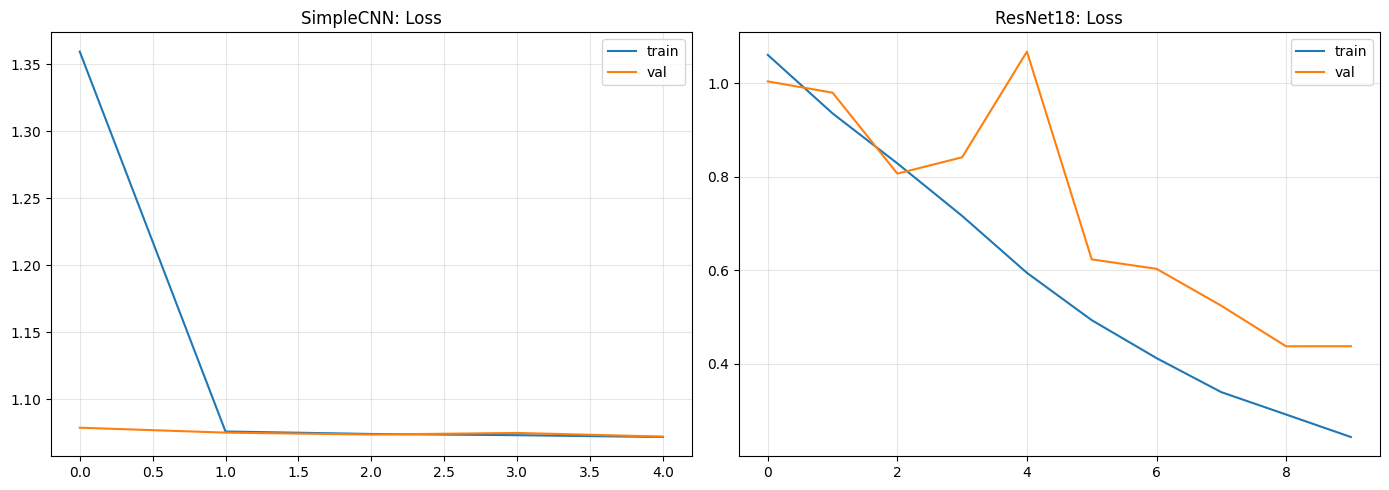

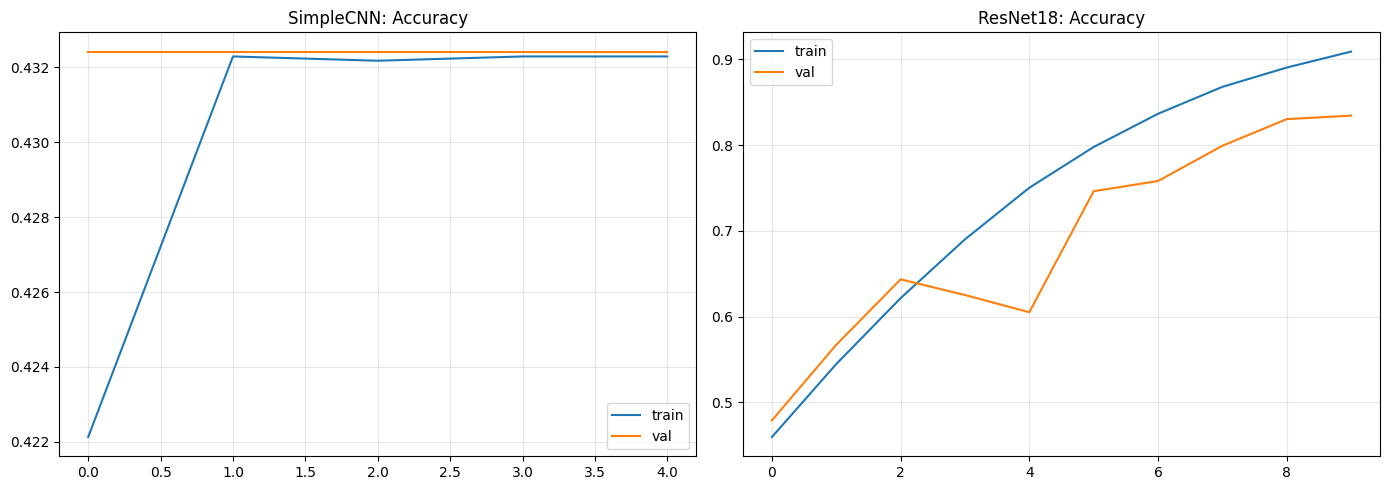

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, hist, title in zip(axes, [hist_cnn, hist_resnet], ["SimpleCNN", "ResNet18"]):
    ax.plot(hist["train_loss"], label="train")
    ax.plot(hist["val_loss"],   label="val")
    ax.set_title(f"{title}: Loss"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, hist, title in zip(axes, [hist_cnn, hist_resnet], ["SimpleCNN", "ResNet18"]):
    ax.plot(hist["train_acc"], label="train")
    ax.plot(hist["val_acc"],   label="val")
    ax.set_title(f"{title}: Accuracy"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**10. Оценка на тесте и матрицы ошибок**


Я оцениваю обе модели на тестовой выборке и строю матрицы ошибок (Confusion Matrix). Из-за того, что в тесте всего 13 картинок класса Thecal Sac, общая точность у ResNet18 составила 38.8%, однако по матрице видно, что модель отлично выучила признаки классов Herniated Disc и No Stenosis. SimpleCNN же просто предсказывает один класс для всех картинок, что дает точность всего 0.0047.

Test Accuracy SimpleCNN: 0.0047
Test Accuracy ResNet18:  0.3882


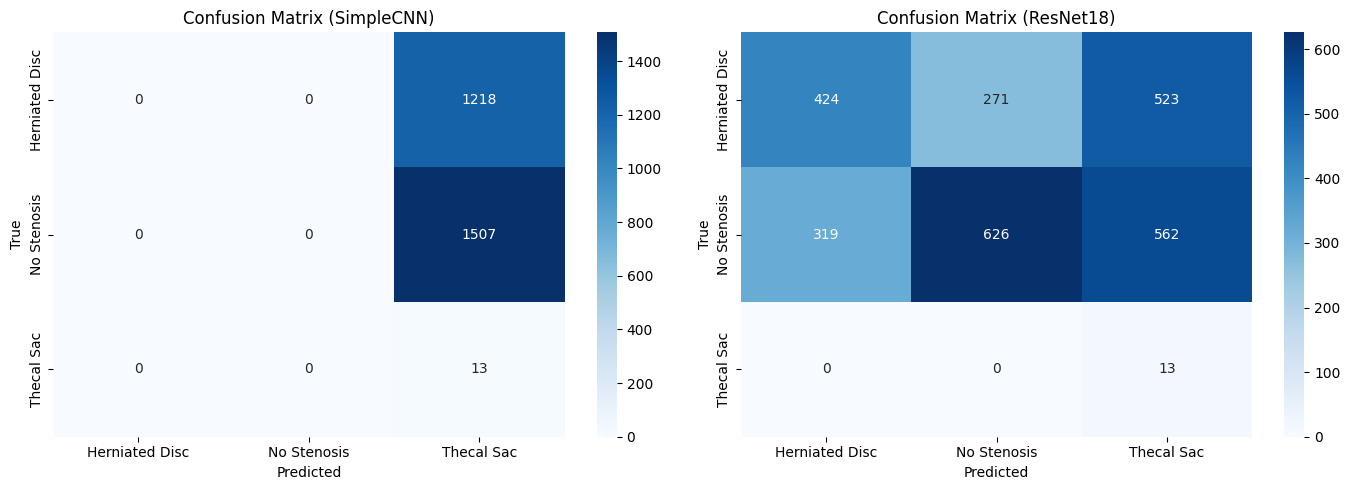

Classification Report: SimpleCNN
                precision    recall  f1-score   support

Herniated Disc       0.00      0.00      0.00      1218
   No Stenosis       0.00      0.00      0.00      1507
    Thecal Sac       0.00      1.00      0.01        13

      accuracy                           0.00      2738
     macro avg       0.00      0.33      0.00      2738
  weighted avg       0.00      0.00      0.00      2738


Classification Report: ResNet18
                precision    recall  f1-score   support

Herniated Disc       0.57      0.35      0.43      1218
   No Stenosis       0.70      0.42      0.52      1507
    Thecal Sac       0.01      1.00      0.02        13

      accuracy                           0.39      2738
     macro avg       0.43      0.59      0.33      2738
  weighted avg       0.64      0.39      0.48      2738



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [14]:
criterion = nn.CrossEntropyLoss()

_, acc_cnn, y_true_cnn, y_pred_cnn = evaluate(cnn_model,    test_loader, criterion)
_, acc_res, y_true_res, y_pred_res = evaluate(resnet_model, test_loader, criterion)

print(f"Test Accuracy SimpleCNN: {acc_cnn:.4f}")
print(f"Test Accuracy ResNet18:  {acc_res:.4f}")

#Confusion matrix для обеих
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, y_true, y_pred, ttl in zip(
        axes,
        [y_true_cnn, y_true_res],
        [y_pred_cnn, y_pred_res],
        ["SimpleCNN", "ResNet18"]):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d',
                xticklabels=classes, yticklabels=classes,
                cmap='Blues', ax=ax)
    ax.set_title(f"Confusion Matrix ({ttl})")
    ax.set_ylabel("True"); ax.set_xlabel("Predicted")
plt.tight_layout(); plt.show()

#Classification reports
print("Classification Report: SimpleCNN")
print(classification_report(y_true_cnn, y_pred_cnn, target_names=classes))

print("\nClassification Report: ResNet18")
print(classification_report(y_true_res, y_pred_res, target_names=classes))

**11. Итоговое сравнение**


В финальном блоке я собираю все ключевые метрики в единую таблицу DataFrame и строю столбчатую диаграмму. Я сравниваю итоговую точность и количество параметров у двух моделей, чтобы сделать финальный вывод о преимуществах и недостатках каждого подхода. Для сложных медицинских изображений предобученные архитектуры значительно превосходят обучение с нуля.

       Model  Test Accuracy  Params (M)  Best Epoch
0  SimpleCNN       0.004748    6.665091           5
1   ResNet18       0.388240   11.178051           9


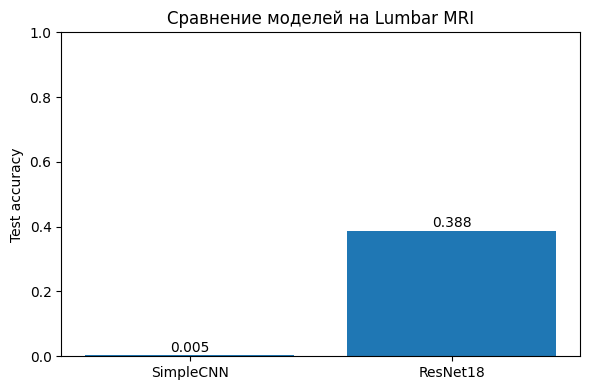

In [15]:
summary = {
    "Model": ["SimpleCNN", "ResNet18"],
    "Test Accuracy": [acc_cnn, acc_res],
    "Params (M)": [
        sum(p.numel() for p in cnn_model.parameters()) / 1e6,
        sum(p.numel() for p in resnet_model.parameters()) / 1e6,
    ],
    "Best Epoch": [
        int(np.argmin(hist_cnn["val_loss"])) + 1,
        int(np.argmin(hist_resnet["val_loss"])) + 1,
    ],
}

import pandas as pd
df_summary = pd.DataFrame(summary)
print(df_summary)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(df_summary["Model"], df_summary["Test Accuracy"])
ax.set_ylim(0, 1); ax.set_ylabel("Test accuracy")
ax.set_title("Сравнение моделей на Lumbar MRI")
for i, v in enumerate(df_summary["Test Accuracy"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha='center')
plt.tight_layout(); plt.show()